In [33]:
import kagglehub
import pandas as pd
import seaborn as sns
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader


kagglehub.login()
# Download latest version
path = kagglehub.competition_download('fall-2026-ecse-551-task-1')

print("Path to competition files:", path)

Path to competition files: /root/.cache/kagglehub/competitions/fall-2026-ecse-551-task-1


In [34]:
PATH = "/root/.cache/kagglehub/competitions/fall-2026-ecse-551-task-1"

train = pd.read_csv(PATH+"/train.csv")
test = pd.read_csv(PATH+"/test.csv")

Y_train = train["label_name"]
X_train = train["image_path"]
X_test = test["id"]

def clean_path(path) :
  clean_path = path[7:]
  clean_path = "archive/RIVAL10_Kaggle" + clean_path
  return clean_path

def clean_path_test(path):
  path = "archive/RIVAL10_Kaggle/test/test_images/" + path
  return path

X_train = X_train.apply(clean_path)
X_test = X_test.apply(clean_path_test)

print(X_train)
print(X_test)
print(Y_train)

0        archive/RIVAL10_Kaggle/train/ordinary/n0446766...
1        archive/RIVAL10_Kaggle/train/ordinary/n0164437...
2        archive/RIVAL10_Kaggle/train/ordinary/n0212339...
3        archive/RIVAL10_Kaggle/train/ordinary/n0269037...
4        archive/RIVAL10_Kaggle/train/ordinary/n0153282...
                               ...                        
21093    archive/RIVAL10_Kaggle/train/ordinary/n0310024...
21094    archive/RIVAL10_Kaggle/train/ordinary/n0212407...
21095    archive/RIVAL10_Kaggle/train/ordinary/n0153282...
21096    archive/RIVAL10_Kaggle/train/ordinary/n0269037...
21097    archive/RIVAL10_Kaggle/train/ordinary/n0242302...
Name: image_path, Length: 21098, dtype: object
0       archive/RIVAL10_Kaggle/test/test_images/00000.png
1       archive/RIVAL10_Kaggle/test/test_images/00001.png
2       archive/RIVAL10_Kaggle/test/test_images/00002.png
3       archive/RIVAL10_Kaggle/test/test_images/00003.png
4       archive/RIVAL10_Kaggle/test/test_images/00004.png
              

# Checking stats about the data

,count
label_name,
frog,2127
bird,2126
car,2126
equine,2122
cat,2122
dog,2119
ship,2119
deer,2116
plane,2110


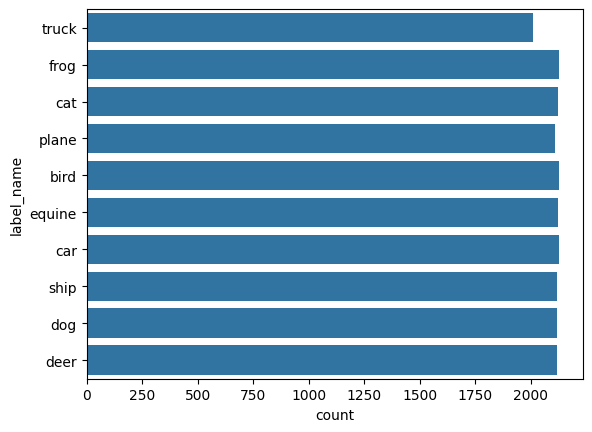

In [35]:
g = sns.countplot(Y_train)

Y_train.value_counts()

In [36]:
def read_image(path) :
  return np.array(Image.open(PATH+"/"+path).convert("RGB"))


In [ ]:
(X_train == "").any()
#check no test has null

np.False_

In [ ]:
print(read_image(X_train[0]).shape)
print(read_image(X_train[0]).max())
print(read_image(X_train[0]).min())

(224, 224, 3)
255
0


# Prepare Data for pytorch

In [37]:
#Prepare Data
X_train = X_train.apply(read_image)
X_test = X_test.apply(read_image)

In [38]:
encodings={
    "truck":0,
    "frog":1,
    "cat":2,
    "plane":3,
    "bird":4,
    "car":5,
    "equine":6,
    "ship":7,
    "deer":8,
    "dog":9,
}

reverse_encodings = {v: k for k, v in encodings.items()}

Y_train = Y_train.replace(encodings)

/tmp/ipykernel_18514/3032436159.py:16: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  Y_train = Y_train.replace(encodings)


In [ ]:
X_train = torch.tensor(X_train[:1000]).float()
X_train = X_train.permute(0, 3, 1, 2)
Y_train = torch.tensor(Y_train[:1000])
train_loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=64, shuffle=True)

X_test = torch.tensor(X_test).float()


# Define Model

In [ ]:
class CNN(nn.Module) :
  def __init__(self) :
    super().__init__()
    self.conv1 = nn.Conv2d(in_channels=3, out_channels=96, kernel_size=11, padding=0, stride=4)
    #out channels = nombre de filtres
    #in channels = les trois couleurs
    # Question : ou sont passés les couleurs ?
    self.relu = nn.ReLU()
    self.pool = nn.MaxPool2d(2)
    self.flatten = nn.Flatten()
    self.linear = nn.LazyLinear(10)


  def forward(self, x) :
    x = self.conv1(x)
    x = self.relu(x)
    x = self.pool(x)
    x = self.flatten(x)
    x = self.linear(x)
    return x


# Train Model

In [ ]:
device="cuda"
model = CNN().to(device)

loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(10):
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        loss = loss_fn(model(xb), yb)
        opt.zero_grad()
        loss.backward()
        opt.step()
    print(epoch, loss.item())

# Evaluate Model

In [ ]:
model.eval()
with torch.no_grad():
  X_test = torch.tensor(X_test[10]).float()
  predictions = model(X_test)

In [ ]:
print(predictions)